# Hunting for a Transition State

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch4/4C-butadiene/ch4C-D-butadieneTS.ipynb)
:::

(ts-search-butadiene-start)=
## Finding a Place that Doesn't Exist

**Transition states** are not stable structures. Transition state theory argues that they **do not exist**; they cannot be involved in any events other than moving from the start to finish of the reaction that they define. We have seen several techniques for **inferring** the structure of transition states in your chemistry courses. One example is Hammond's postulate. Using computational chemistry we can **calculate** the structure of a **transition state**. Math is very good at describing the indescribable.

## Setting up this Notebook

The collapsed [code cell below](#setup-cell-butadiene-TS) will **load in** all the *Python* packages and set global variables for the calculations in this notebook. If you are using *Colab*, **run this cell first**, watch it eventually crash, and then **run it again** and you will be set up.

In [35]:
#| label: setup-cell-butadiene-TS
#| tags: [remove-output, hide-input]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import json

import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

# The load data for this notebook
if IN_COLAB and not Path("data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json").exists():
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631-C2.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# a function to collect the zmatrix variables into a dictionary using the text zmatrix in the mol object.
def zmat_variables(mol):
    """Return the Z-matrix variables of mol as a {name: value} dictionary."""
    text = mol.create_psi4_string_from_molecule()
    variables = text.split("\n\n", 1)[1]     # the variable are separated by a blank line. We will split the text block here and use the second part (position [1])
    zvars = {}
    for line in variables.strip().splitlines():
        name, value = line.split("=")
        zvars[name.strip()] = float(value)
    return zvars

# a function to extract data from the psi4 variables and the mol object and return a dictionary of results
def get_results(mol):
    # get results. We will put them in a list; one set of results for each calculation.
    steps = psi4.variable("OPTIMIZATION ITERATIONS") # record how many steps were taken to reach teh optimized structure
    D = mol.get_variable("D")
    
    # extract orbital energies from wfn
    eps = wfn.epsilon_a_subset("AO", "ALL").np  # get list of all orbital energies without grouping them by symmetry
    homo = eps[wfn.nalpha() - 1]                # wfn.nalpha() returns number of 'alpha' electrons. Will be same a number of filled orbitals. had to subtract 1 because python started the list from position zero. So position 14 is the 15th MO.
    lumo = eps[wfn.nalpha()]

    # collect symmetry
    point_group = mol.get_full_point_group()
    sym = mol.schoenflies_symbol()   # get symmetry point group used by calculation

    # get zmatrix text string from resulting mol object
    z = mol.create_psi4_string_from_molecule()
    xyz = mol.save_string_xyz_file()

    # extract structural information from the z-matrix
    variables = zmat_variables(mol)  # returns a dictionary of all zmat variables

    # add to `results` list to create data object with all the results
    results = {
        "D": D,
        "E": E,
        "steps": steps,
        "E_homo": homo,
        "E_lumo": lumo,
        "sym": sym,
        "PG": point_group,
        "xyz": xyz,
        "Z": z,
        "var": variables
    }

    return(results)

# a function to print selected data from the result dictionary
def print_results(results):
    print(f"Dihedral, D = {results["D"]:.2f} degrees")
    print(f"Energy = {results["E"]:.10f} Hartee")
    print(f"steps in optimization: {int(results["steps"])}")
    print(f"Symmetry point group: {results["PG"]}")
    print()
    print("Z-matrix variables after optimization")
    print(results["Z"].split("\n\n")[1])


# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

(json-to-plots-butadiene-TS)=
## Get the Data and Set the Scene

We will **load** in data from the [previous rotational scan](ch4C-B-butadiene.ipynb#Alternate_scan_C2) performed with `B3LYP-D3BJ/6-31G*` at $C_2$ symmetry. Then I will [plot the rotational energy profile](#plotting-energy-butadiene-TS-start) and [display the structures](#scan-viewer-butadiene-TS-start) in the **scan** for reference. I will also provide the [numbering scheme](#fig-zmatrix-butadiene-scan-TS) for the Z-matrix that was used in the rotational **scan**.



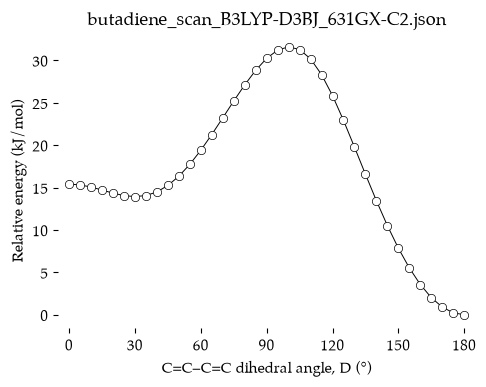

In [36]:
#| label: plotting-energy-butadiene-TS-start
#| tags: [hide-input]
#| caption: Plot of energies for rotational scan of butadiene. Data is for the `B3LYP-D3BJ/6-31G*` at $C_2$ symmetry.

name = "butadiene_scan_B3LYP-D3BJ_631GX-C2.json"
with open(data_dir / name) as f:
    scan = json.load(f)            # load data into the object named 'scan'


scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
Ds = [point["D"] for point in scan]
Es = [point["E"] for point in scan]              # hartree
E_min = min(Es)
E_rel = [(E - E_min) * psi4.constants.hartree2kJmol for E in Es]       # kJ/mol relative to the lowest point


fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))

ax.plot(Ds, E_rel, color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Relative energy (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
ax.set_title(name)

plt.show()


In [37]:
#| label: scan-viewer-butadiene-TS-start
#| tags: [hide-input]
#| caption: Structure of butadiene at each point of the rotational scan. Drag the slider or press Play.

name = "B3LYP_C2"                  # any key in data, e.g. "HF_C2"

scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

# Energy of each point relative to the lowest, in kJ/mol, for the label beside the slider
Es = np.array([point["E"] for point in scan])
E_rel = (Es - Es.min()) * psi4.constants.hartree2kJmol
labels = [f"D = {point['D']:5.1f}°   ΔE = {e:4.1f} kJ/mol" for point, e in zip(scan, E_rel)]

# One frame per scan point; line every frame up on atoms 1, 2 and 3 so only the far end turns
scan_xyz = ph.scan_to_xyz([point["xyz"] for point in scan], labels, align=[1, 2, 3])
ph.show_scan(scan_xyz, interactive=INTERACTIVE, interval=150)

3Dmol.js failed to load for some reason. Please check your browser console for error messages. 
 

 
 Play

:::{figure} images/Z-matrixButadiene2.png
:label: fig-zmatrix-butadiene-scan-TS
:width: 50%
:align: center
:alt: z-matrix diagram of butadiene

A diagram of the layout of the molecular geometry for building the Z-matrix. 
:::

There are two **local** points of **minimum** energy: at `D = 180` (the $C_{2h}$ *s-trans* geometry) and near `D = 35` (the *s-cis* structure with the **minimum** energy). We now have all the **information** that we need to **start**.

## Minima for *s-trans* Geometry

Let us **begin** with `D = 180`. There are **two ways** to approach the energy of the minimum. We can optimize at $C_2$ symmetry and allow the optimizer to **decide** how flat is best, or force perfect $C_{2h}$ symmetry and have a **perfect** flat molecule. Let us do **both**. We will start with the $C_{2h}$ **symmetry**, and then we will **tweak** it and re-optimize to allow for optimization at the lower $C_{2}$ **symmetry**. 

### Optimization in $C_{2h}$ Symmetry

The [code below](#butadiene-c2h-optimization-perfect-TS) will start with a **perfectly** flat version of *s-trans* butadiene that has **enforced** $C_2$ symmetry through the use of paired **variables**. This is the **same** calculation as we have seen in a [previous optimization for butadiene](ch4C-B-butadiene.ipynb#a-better-Z-matrix-butadiene) at $C_{2h}$ **symmetry**.

In [38]:
#| label: butadiene-c2h-optimization-perfect-TS
#| tags: [hide-input]

# Resources for every calculation on this page (house limits: 4 GB, 4 threads; 2 threads on Colab)
psi4.set_memory("4 GB")
psi4.set_num_threads(2)

# make z-matrix the defines C_2 symmetry
zmat = '''
0 1
C
C   1  rCCterm
C   2  rCCcent      1  aCCC
C   3  rCCterm      2  aCCC         1  D
H   1  rCHtermen    2  aHCCendo     3  tHCCCendo
H   1  rCHtermex    5  aHCHterm     2  tHCHC
H   2  rCHcent      1  aHCCcent     3  tHCCCcent
H   3  rCHcent      4  aHCCcent     2  tHCCCcent
H   4  rCHtermen    3  aHCCendo     2  tHCCCendo
H   4  rCHtermex    9  aHCHterm     3  tHCHC

rCCcent = 1.5
rCCterm = 1.4
rCHtermen = 1.1
rCHtermex = 1.1
rCHcent = 1.1
aCCC = 120
aHCCendo = 120
aHCHterm = 120
aHCCcent = 120
tHCCCendo  =   0.0
tHCHC  = 180.0
tHCCCcent = 180.0
D   = 180
'''

# apply Z-matrix to construct molecule object
mol = psi4.geometry(zmat)

# PSI4 settings
psi4.set_output_file(output_dir / f"ch4C-D-butadiene_c2h.out", False) # filenames will be "butadiene_00X.out"

# optimize and return energy and a wavefunction object
E, wfn = psi4.optimize("B3LYP-D3BJ/6-31G*", molecule = mol, return_wfn = True) 

results_C2h = get_results(mol)

# choose a name to save the file. I used the following when I performed the calculations
name = "ch4C-D-butadiene_C2h-B3LYP-D3BJ_631GX.json"

# Save the `results` object as json format so the scan doesn't have to be re-run
with open(data_dir / name, "w") as f:
    json.dump(results_C2h, f, indent=2)

print(f"saved json file to {name}")
print("-------------------------")
print_results(results_C2h)

Optimizer: Optimization complete!
saved json file to ch4C-D-butadiene_C2h-B3LYP-D3BJ_631GX.json
-------------------------
Dihedral, D = -180.00 degrees
Energy = -156.0029287982 Hartee
steps in optimization: 5
Symmetry point group: C2h

Z-matrix variables after optimization
    D         = -180.0000000000
    aCCC      =  124.1903287309
    aHCCcent  =  119.5546505297
    aHCCendo  =  121.4350750039
    aHCHterm  =  116.7091648973
    rCCcent   =    1.4564140271
    rCCterm   =    1.3400932665
    rCHcent   =    1.0902695659
    rCHtermen =    1.0877584269
    rCHtermex =    1.0855601969
    tHCCCcent =  180.0000000000
    tHCCCendo =   -0.0000000000
    tHCHC     = -180.0000000000


### Optimization in $C_{2}$ Symmetry

Now I will **repeat** the optimization again but **tweak** the dihedral angle so that we are no longer **trapped** in $C_{2h}$ symmetry.

In [39]:
#| label: butadiene-c2-optimization-perfect-TS
#| tags: [hide-input]

psi4.set_output_file(output_dir / f"ch4C-D-butadiene_c2.out", False) # filenames will be "butadiene_00X.out"

mol.set_variable("D", 179.0) # set the torsion angle in the zmatrix of the mol object

# optimize and return energy and a wavefunction object
E, wfn = psi4.optimize("B3LYP-D3BJ/6-31G*", molecule = mol, return_wfn = True) 

results_C2 = get_results(mol)

# choose a name to save the file. I used the following when I performed the calculations
name = "ch4C-D-butadiene_C2-B3LYP-D3BJ_631GX.json"

# Save the `results` object as json format so the scan doesn't have to be re-run
with open(data_dir / name, "w") as f:
    json.dump(results_C2, f, indent=2)

print(f"saved json file to {name}")
print("-------------------------")
print_results(results_C2)


Optimizer: Optimization complete!
saved json file to ch4C-D-butadiene_C2-B3LYP-D3BJ_631GX.json
-------------------------
Dihedral, D = 179.79 degrees
Energy = -156.0029281773 Hartee
steps in optimization: 29
Symmetry point group: C2

Z-matrix variables after optimization
    D         =  179.7880690679
    aCCC      =  124.1672052489
    aHCCcent  =  119.6127872160
    aHCCendo  =  121.4133215457
    aHCHterm  =  116.7368331229
    rCCcent   =    1.4563791831
    rCCterm   =    1.3400802318
    rCHcent   =    1.0901056155
    rCHtermen =    1.0877620747
    rCHtermex =    1.0855624060
    tHCCCcent =  179.8517682835
    tHCCCendo =    0.0899261597
    tHCHC     = -179.9874046938


We see that the geometry and energies are almost **exactly** the **same**. Is the perfect lower in energy than the **almost** perfect? Let us see...

In [40]:
E_diff = (results_C2h["E"]-results_C2["E"]) * psi4.constants.hartree2kJmol
print(f"The change in energy from C_2 to C2h is {E_diff:.7f} kJ/mole")

The change in energy from C_2 to C2h is -0.0016302 kJ/mole


The **difference** in energy is **insignificant**. It's basicly zero. The perfect structure is lower in energy by an immeasurable amount. But we can say that the $C_{2h}$ is the **lowest** energy **geometry** for the *s-trans* conformer.

## Minima for *s-cis* Geometry

The $C_{2v}$ **planar** geometry for the *s-cis* conformer at `D = 0` is **not** an energy **minimum**. The energy cost for steric clash of the two *endo* C–H bonds on the terminal carbon atoms to too great. In the **rotational** scan, we do see an energy minimum nearby at `D ≈ 35`. 

### Picking the Lowest Energy Geometry

We can attempt to **find** the lowest point in our scan using the [following code](#butadiene-s-cis-optimization-picker-TS).


In [41]:
#| label: butadiene-s-cis-optimization-picker-TS
#| tags: [hide-input]

lowest_E = results_C2h["E"]     # the lowest energy conformation in the scan

# load in data from rotational scan
name = "butadiene_scan_B3LYP-D3BJ_631GX-C2.json"
with open(data_dir / name) as f:
    scan = json.load(f)            # load data into the object named 'scan'

# make use that the dictionaries are in order of energy
scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

# set a range on either side of target loacl minimum and fin the lowest E value in that range
lo, hi = 20, 60                                   # window around D = 35
near = [p for p in scan if lo <= p["D"] <= hi]    # collect points on either side of loacl min
best = min(near, key=lambda p: p["E"])            # choose the object in near that contains the lowert value for near["E"]
dE = (best['E'] - lowest_E) * psi4.constants.hartree2kJmol

print(f"lowest point: D = {best['D']:.1f}°, ΔE = {dE:.2f} kJ/mole")

lowest point: D = 30.0°, ΔE = 13.91 kJ/mole


We only have data at `D = 25, 30, 35`, etc. The **minimum** could be at 33°, between these set values for `D`. How do we check in-between?

### A Curve Fit for the Lowest Energy

We can **fit** the points on either side of the energy well to a **parabolic** function and then **find** the minimum for that function. In the code below, the curve-fit minimum was close to `D = 30`.

In [42]:
#| label: butadiene-s-cis-optimization-curve-TS
#| tags: [hide-input]

lowest_E = results_C2h["E"]     # the lowest energy conformation in the scan

# load in data from rotational scan
name = "butadiene_scan_B3LYP-D3BJ_631GX-C2.json"
with open(data_dir / name) as f:
    scan = json.load(f)            # load data into the object named 'scan'

# make use that the dictionaries are in order of energy
scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

# set a range on either side of target loacl minimum and fin the lowest E value in that range
lo, hi = 20, 60                                   # window around D = 35
near = [p for p in scan if lo <= p["D"] <= hi]    # collect points on either side of loacl min
best = min(near, key=lambda p: p["E"])            # choose the object in near that contains the lowert value for near["E"]

i = Ds.index(best["D"])                           # index value (position) in the sorted list of results
x = np.array(Ds[i-1:i+2])
y = np.array(Es[i-1:i+2])
a, b, c = np.polyfit(x, y, 2)                     # y = a x^2 + b x + c
D_fit = -b / (2*a)
E_fit = np.polyval([a, b, c], D_fit)

dE_fit = (best['E'] - lowest_E) * psi4.constants.hartree2kJmol

print(f"interpolated minimum: D = {D_fit:.2f}°, ΔE = {dE_fit:.2f} kJ/mole")

interpolated minimum: D = 29.96°, ΔE = 13.91 kJ/mole


### Optimizing the *S-cis* Conformer

Rather than try to **tease** out the energy value for the **local minimum** near `D = 35`, we could **set** that value in the geometry and then **optimize**. The optimizer will find the nearest **low point** in the energy surface. 

In [43]:
#| label: butadiene-c2-optimization-s-cis-TS
#| tags: [hide-input]

lowest_E = results_C2h["E"]     # the lowest energy conformation in the scan

psi4.set_output_file(output_dir / f"ch4C-D-butadiene_s-cis.out", False) # filenames will be "butadiene_00X.out"

mol.set_variable("D", 35) # set the torsion angle in the zmatrix of the mol object

# optimize and return energy and a wavefunction object
E, wfn = psi4.optimize("B3LYP-D3BJ/6-31G*", molecule = mol, return_wfn = True) 

results_s_cis = get_results(mol)

# choose a name to save the file. I used the following when I performed the calculations
name = "ch4C-D-butadiene_s-cis-B3LYP-D3BJ_631GX.json"

# Save the `results` object as json format so the scan doesn't have to be re-run
with open(data_dir / name, "w") as f:
    json.dump(results_s_cis, f, indent=2)

lowest_E = results_C2h["E"]     # the lowest energy conformation in the scan

print(f"saved json file to {name}")
print()

dE_fit = (E - lowest_E) * psi4.constants.hartree2kJmol

print(f"optimized minimum: D = {results_s_cis["D"]:.2f}°, ΔE = {dE_fit:.2f} kJ/mole")

print("-------------------------")
print_results(results_s_cis)


Optimizer: Optimization complete!
saved json file to ch4C-D-butadiene_s-cis-B3LYP-D3BJ_631GX.json

optimized minimum: D = 30.25°, ΔE = 13.92 kJ/mole
-------------------------
Dihedral, D = 30.25 degrees
Energy = -155.9976251864 Hartee
steps in optimization: 6
Symmetry point group: C2

Z-matrix variables after optimization
    D         =   30.2454401486
    aCCC      =  125.5257530719
    aHCCcent  =  118.6739630144
    aHCCendo  =  121.6587360366
    aHCHterm  =  116.8216579529
    rCCcent   =    1.4690913490
    rCCterm   =    1.3387118169
    rCHcent   =    1.0901978495
    rCHtermen =    1.0870107025
    rCHtermex =    1.0859003424
    tHCCCcent = -178.6929862202
    tHCCCendo =    2.0661587158
    tHCHC     = -179.3014543968


In [44]:
Ds.index(best["D"]) 

6